# Computational Physics Project: Numerical Analysis of Optical Waveguide Eigenmodes

This single notebook contains the complete project in a progressive order:

1. **1D slab waveguide:** scalar Helmholtz equation, finite-difference eigenvalue method, mode profiles and core-width study.
2. **2D rectangular waveguide:** two-dimensional finite-difference operator, sparse eigenmodes, field visualisations and core-width study.
3. **2D multilayer-cladding design:** a parameter sweep that maximises the core confinement factor, with a heatmap of the design search.
4. **Monte Carlo material search:** random sampling of three ordered cladding refractive indices for a fixed multilayer geometry, with an effective-index distribution plot.

The same scalar-wave model is used throughout. The multilayer thickness sweep and Monte Carlo material search are **2D calculations** and reuse the 2D solver. The Monte Carlo search targets an effective-index range; it is not a proof of a global optimum.

Run the notebook from top to bottom because later sections reuse variables and functions defined earlier.


## Part I — One-Dimensional Slab Waveguide

The 1D model is the starting point: it establishes the governing equation, finite-difference matrix and interpretation of eigenmodes before moving to a more complex 2D cross-section.

### 1. Selection of the Physics Problem

The problem selected for this project is the numerical determination of eigenmodes in a one-dimensional slab optical waveguide.

A slab waveguide has a thin high-refractive-index core between two lower-index cladding layers. Light is confined along x and travels along z.

The objective is to calculate the transverse electric-field profile of the guided mode and its propagation constant, and to see how the core width affects the effective refractive index.

### 2. Physics of the Problem

Assuming propagation along z, the field is written as:

$$
E(x,z)=\psi(x)e^{i\beta z}
$$

Substituting this into the scalar Helmholtz equation gives:

$$
\frac{d^2\psi}{dx^2}+\left[k_0^2n^2(x)-\beta^2\right]\psi=0
$$

Here $\psi(x)$ is the transverse field, $\beta$ is the propagation constant and $k_0=2\pi/\lambda$. The effective index is $n_{\mathrm{eff}}=\beta/k_0$.

A mode is guided when $n_{\mathrm{cladding}}<n_{\mathrm{eff}}<n_{\mathrm{core}}$. The field then oscillates inside the core and decays in the cladding.

### 3. Finite Difference Method

The domain is divided into a uniform grid and the refractive index is assigned to each point. The second derivative is approximated using the central difference:

$$
\frac{d^2\psi}{dx^2}\approx\frac{\psi_{i+1}-2\psi_i+\psi_{i-1}}{\Delta x^2}
$$

This turns the Helmholtz equation into a matrix eigenvalue problem:

$$
A\boldsymbol{\psi}=\beta^2\boldsymbol{\psi},\qquad A=D+k_0^2\operatorname{diag}(n^2)
$$

where $D$ is the tridiagonal second-derivative matrix. The field is taken as zero at the two ends of the domain, so only the interior points are unknowns. The eigenvalues of $A$ give $\beta^2$ and the eigenvectors give the field profiles. They are found using the sparse solver `eigsh()` from SciPy.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import eigsh

n_core = 1.50
n_cladding = 1.45

wavelength = 1.55e-6
k0 = 2*np.pi/wavelength

core_width = 2e-6

L = 10e-6
N = 501

x = np.linspace(-L/2, L/2, N)
dx = x[1] - x[0]

#only inner points are unknowns since field is zero at the ends
x_inner = x[1:-1]
N_inner = len(x_inner)

n = np.full(N_inner, n_cladding)
n[np.abs(x_inner) <= core_width/2] = n_core

print("Free space wave number:", k0, "m^-1")
print("Grid spacing dx =", dx*1e6, "micrometres")
print("Total unknowns:", N_inner)

Free space wave number: 4053667.940115862 m^-1
Grid spacing dx = 0.01999999999999981 micrometres
Total unknowns: 499


In [ ]:
main_diag = -2*np.ones(N_inner)/dx**2
off_diag = np.ones(N_inner - 1)/dx**2

D = diags([off_diag, main_diag, off_diag], offsets=[-1, 0, 1], format="csr")

A = D + diags(k0**2 * n**2, offsets=0, format="csr")

print("Matrix A shape:", A.shape)

Matrix A shape: (499, 499)


In [ ]:
num_modes = 10

eigenvalues, eigenvectors = eigsh(A, k=num_modes, which="LA")

order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

beta = np.sqrt(np.maximum(eigenvalues, 0))
neff = beta/k0

guided = (neff > n_cladding) & (neff < n_core)

print("Calculated eigenmodes:\n")

for i in range(num_modes):
    status = "Guided-mode candidate" if guided[i] else "Outside guided range"
    print(f"Mode {i+1}: beta = {beta[i]:.6e} m^-1, neff = {neff[i]:.6f}, {status}")

Calculated eigenmodes:

Mode 1: beta = 6.008912e+06 m^-1, neff = 1.482340, Guided-mode candidate
Mode 2: beta = 5.866644e+06 m^-1, neff = 1.447243, Outside guided range
Mode 3: beta = 5.827555e+06 m^-1, neff = 1.437600, Outside guided range
Mode 4: beta = 5.783421e+06 m^-1, neff = 1.426713, Outside guided range
Mode 5: beta = 5.691695e+06 m^-1, neff = 1.404085, Outside guided range
Mode 6: beta = 5.615465e+06 m^-1, neff = 1.385280, Outside guided range
Mode 7: beta = 5.483652e+06 m^-1, neff = 1.352763, Outside guided range
Mode 8: beta = 5.359683e+06 m^-1, neff = 1.322181, Outside guided range
Mode 9: beta = 5.197757e+06 m^-1, neff = 1.282235, Outside guided range
Mode 10: beta = 5.010586e+06 m^-1, neff = 1.236062, Outside guided range


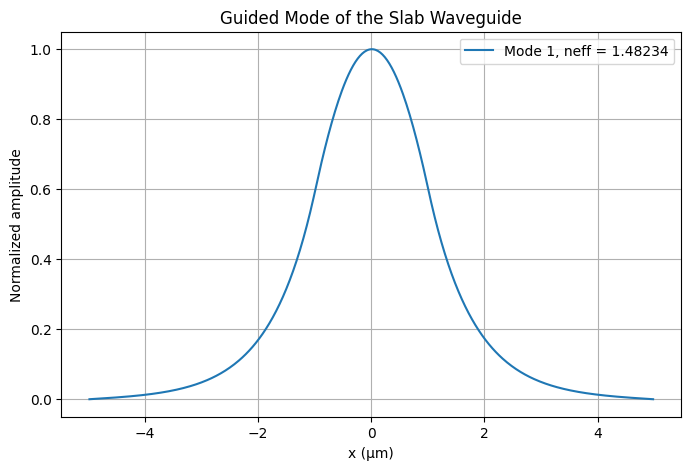

In [ ]:
plt.figure(figsize=(8, 5))

for j in np.where(guided)[0]:
    psi = eigenvectors[:, j]
    psi = psi/np.max(np.abs(psi))

    plt.plot(x_inner*1e6, psi, label=f"Mode {j+1}, neff = {neff[j]:.5f}")

plt.xlabel("x (μm)")
plt.ylabel("Normalized amplitude")
plt.title("Guided Mode of the Slab Waveguide")
plt.legend()
plt.grid(True)

plt.show()

### 4. Results and Physical Interpretation

For the selected waveguide only the first mode has an effective index between the cladding index (1.45) and the core index (1.50), with $n_{\mathrm{eff}}\approx1.4823$. This is the fundamental mode. Its field is a single lobe peaked at the centre of the core and it decays into the cladding.

The other eigenvalues give $n_{\mathrm{eff}}<1.45$, so they are not guided.

### 5. Extension: Effect of Core Width on the Effective Index

The core width is varied while the refractive indices, wavelength and computational domain are kept constant. For each width the index profile and matrix are rebuilt and the largest eigenvalue gives the fundamental-mode effective index.

A wider core confines the mode better, so $n_{\mathrm{eff}}$ moves closer to the core index. For a very thin core the mode spreads into the cladding and $n_{\mathrm{eff}}$ approaches the cladding index.

In [ ]:
def calculate_fundamental_neff(width):

    n_test = np.full(N_inner, n_cladding)
    n_test[np.abs(x_inner) <= width/2] = n_core

    A_test = D + diags(k0**2 * n_test**2, offsets=0, format="csr")

    values, vectors = eigsh(A_test, k=1, which="LA")

    return np.sqrt(max(values[0], 0))/k0


widths_um = np.array([0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0])
neff_values = []

for w in widths_um:
    neff_value = calculate_fundamental_neff(w*1e-6)
    neff_values.append(neff_value)

    print(f"Width = {w:.1f} μm, Effective index = {neff_value:.6f}")

Width = 0.5 μm, Effective index = 1.456319
Width = 1.0 μm, Effective index = 1.467509
Width = 2.0 μm, Effective index = 1.482340
Width = 3.0 μm, Effective index = 1.489314


Width = 4.0 μm, Effective index = 1.492902
Width = 5.0 μm, Effective index = 1.494957
Width = 6.0 μm, Effective index = 1.496234


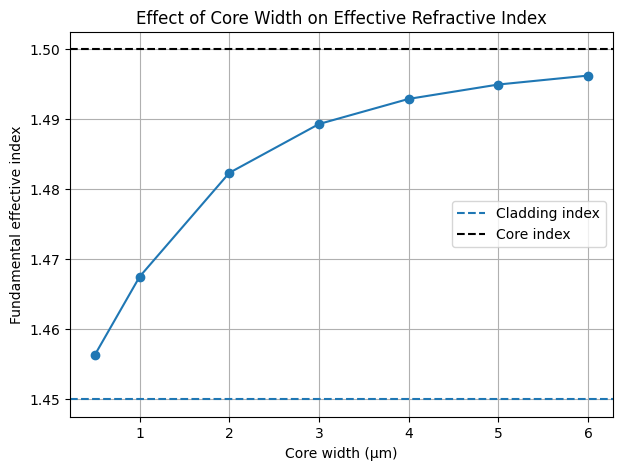

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(widths_um, neff_values, marker="o")

plt.axhline(n_cladding, linestyle="--", label="Cladding index")
plt.axhline(n_core, linestyle="--", color="black", label="Core index")

plt.xlabel("Core width (μm)")
plt.ylabel("Fundamental effective index")
plt.title("Effect of Core Width on Effective Refractive Index")

plt.legend()
plt.grid(True)

plt.show()

## Part II — Two-Dimensional Rectangular Waveguide

The same eigenvalue approach is now extended to a rectangular core with variation in both transverse directions.

### 6. Selection of the 2D Physics Problem

The problem selected for this project is the numerical determination of eigenmodes in a two-dimensional rectangular optical waveguide.

An optical waveguide is a structure designed to confine and guide electromagnetic waves along a particular direction. It consists of a high-refractive-index core surrounded by a lower-refractive-index cladding.

The objective is to calculate the transverse electric-field distributions, known as eigenmodes, and their corresponding propagation constants. These quantities help us understand how electromagnetic waves propagate and remain confined within the waveguide.

The project investigates how the geometry and refractive-index distribution of the waveguide influence its guided modes.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import eigsh

#Refractice indices of core and cladding in optical fibre
n_core=1.50
n_cladding=1.45

wavelength=1.55e-6 #Wave lenght of light

k0=2*np.pi/wavelength

core_width=4e-6
core_height=3e-6

#dimensions of computational domain
lx=12e-6
ly=12e-6

nx=101
ny=101

print("Free space wave number:",k0,"m^-1")

Free space wave number: 4053667.940115862 m^-1


In [ ]:
x=np.linspace(-lx,lx,nx)
y=np.linspace(-ly,ly,ny)

dx=x[1]-x[0]
dy=y[1]-y[0]

#We are imposing field 0 at boundary
x_inner=x[1:-1]
y_inner=y[1:-1]

nx_inner=len(x_inner)
ny_inner=len(y_inner)

X,Y=np.meshgrid(x_inner,y_inner,indexing="xy")

print("Grid spacing dx =", dx * 1e6, "micrometres")
print("Grid spacing dy =", dy * 1e6, "micrometres")

print("Interior grid size:", nx_inner, "x", ny_inner)
print("Total unknowns:", nx_inner * ny_inner)

Grid spacing dx = 0.2399999999999994 micrometres
Grid spacing dy = 0.2399999999999994 micrometres
Interior grid size: 99 x 99
Total unknowns: 9801


In [ ]:
n = np.zeros((ny_inner, nx_inner))
for i in range(ny_inner):
    for j in range(nx_inner):
        n[i, j] = n_cladding

for i in range(ny_inner):
    for j in range(nx_inner):
        if (X[i, j] >= -core_width / 2 and X[i, j] <= core_width / 2 and
            Y[i, j] >= -core_height / 2 and Y[i, j] <= core_height / 2):
            n[i, j] = n_core

core_mask = (
    (np.abs(X) <= core_width / 2) &
    (np.abs(Y) <= core_height / 2)
)

print("Core refractive index:", n_core)
print("Cladding refractive index:", n_cladding)

Core refractive index: 1.5
Cladding refractive index: 1.45


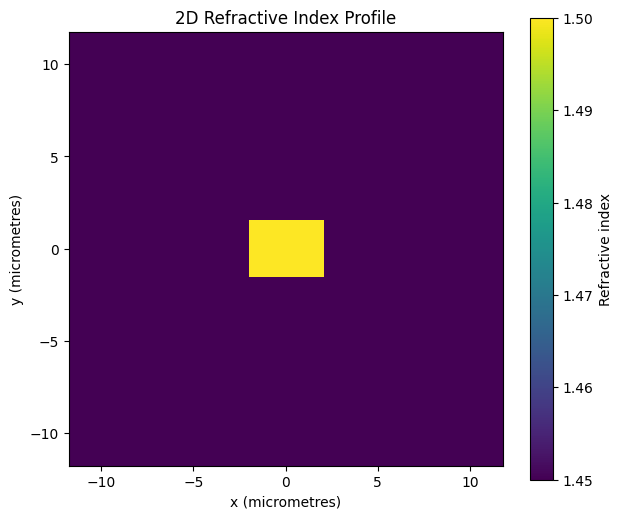

In [ ]:
plt.figure(figsize=(7, 6))

plt.imshow(
    n,
    extent=[
        x_inner[0] * 1e6,
        x_inner[-1] * 1e6,
        y_inner[0] * 1e6,
        y_inner[-1] * 1e6
    ],
    origin="lower",
    cmap="viridis",
    aspect="equal"
)

plt.colorbar(label="Refractive index")

plt.xlabel("x (micrometres)")
plt.ylabel("y (micrometres)")

plt.title("2D Refractive Index Profile")

plt.show()

### 7. Physics and Motivation for Numerical Computation

The propagation of electromagnetic waves in a dielectric waveguide can be described using the Helmholtz equation. Assuming propagation along the z-direction, the electric field is expressed as:

$$
E(x,z)=\psi(x)e^{i\beta z}
$$

Substituting this into the scalar Helmholtz equation gives:

$$
\nabla_\perp^2\psi+
[k_0^2n^2(x,y)-\beta^2]\psi=0
$$

Here, $$\psi(x,y)$$ represents the transverse field distribution and $\beta$ is the propagation constant.

For a simple one-dimensional slab waveguide, analytical solutions can be obtained under suitable assumptions. However, for a two-dimensional rectangular waveguide, determining the eigenmodes becomes considerably more complicated because the field varies in two transverse directions and must satisfy the boundary conditions throughout the structure.

A general rectangular dielectric waveguide does not have a simple closed-form solution for its full modal field distributions. Numerical computation therefore provides a practical method to determine the propagation constants and corresponding field patterns.

In this project, the finite difference method is used to discretize the governing differential equation, converting it into a matrix eigenvalue problem that can be solved computationally.

### 8. Computational Method and Implementation

The two-dimensional computational domain is first divided into a uniform grid using the NumPy library. The refractive-index profile is then defined by assigning a higher refractive index to the rectangular core and a lower refractive index to the surrounding cladding.

The scalar Helmholtz equation is discretized using the central finite difference method. The second derivatives along the x and y directions are approximated using neighbouring grid points.

The resulting derivative matrices are combined using Kronecker products to construct the two-dimensional Laplacian operator.

The complete matrix is constructed as:

$$
A=D_{2D}+k_0^2\operatorname{diag}(n^2)
$$

The discretized wave equation consequently becomes:

$$
A\boldsymbol{\psi}=\beta^2\boldsymbol{\psi}
$$

This eigenvalue problem is solved using the sparse eigenvalue solver `eigsh()` from SciPy. The eigenvalues provide the squares of the propagation constants, while the corresponding eigenvectors provide the transverse field distributions.

The propagation constants are calculated by taking the square roots of the eigenvalues, and the effective refractive indices are obtained using:

$$
n_{\mathrm{eff}}=\frac{\beta}{k_0}
$$

The outer computational boundaries are assigned zero-field boundary conditions, and only the interior grid points are treated as unknowns.

In [ ]:
# Main diagonal coefficients
main_x = -2 * np.ones(nx_inner) / dx**2
main_y = -2 * np.ones(ny_inner) / dy**2

# Upper and lower diagonal coefficients
off_x = np.ones(nx_inner - 1) / dx**2
off_y = np.ones(ny_inner - 1) / dy**2

# Second derivative matrix along x
Dxx = diags(
    [off_x, main_x, off_x],
    offsets=[-1, 0, 1],
    format="csr"
)

# Second derivative matrix along y
Dyy = diags(
    [off_y, main_y, off_y],
    offsets=[-1, 0, 1],
    format="csr"
)

print("Dxx shape:", Dxx.shape)
print("Dyy shape:", Dyy.shape)

Ix = eye(nx_inner, format="csr")
Iy = eye(ny_inner, format="csr")

# Construct the 2D Laplacian
D2D = kron(Iy, Dxx) + kron(Dyy, Ix)

print("2D Laplacian shape:", D2D.shape)

# Convert the 2D refractive index array into a 1D array
n_flat = n.ravel()

# Construct the refractive-index contribution
N_matrix = diags(
    k0**2 * n_flat**2,
    offsets=0,
    format="csr"
)

# Construct the complete eigenvalue matrix
A = D2D + N_matrix

print("Final matrix A shape:", A.shape)
print("Number of non-zero elements:", A.nnz)

Dxx shape: (99, 99)
Dyy shape: (99, 99)
2D Laplacian shape: (9801, 9801)
Final matrix A shape: (9801, 9801)
Number of non-zero elements: 48609


In [ ]:
# Number of eigenvalues and eigenvectors to calculate
num_modes = 9

# Solve the eigenvalue problem
eigenvalues, eigenvectors = eigsh(
    A,
    k=num_modes,
    which="LA"
)

# Sort eigenvalues in descending order
order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Calculate propagation constants
beta = np.sqrt(np.maximum(eigenvalues, 0))

# Calculate effective refractive indices
neff = beta / k0

In [ ]:
# A basic effective-index condition for guided modes
guided_mask = (
    (neff > n_cladding) &
    (neff < n_core)
)

print("Calculated eigenmodes:\n")

for i in range(num_modes):

    if guided_mask[i]:
        status = "Guided-mode candidate"
    else:
        status = "Outside guided range"

    print(
        f"Mode {i+1}: "
        f"beta = {beta[i]:.6e} m^-1, "
        f"neff = {neff[i]:.6f}, "
        f"{status}"
    )

Calculated eigenmodes:

Mode 1: beta = 6.012594e+06 m^-1, neff = 1.483248, Guided-mode candidate
Mode 2: beta = 5.936036e+06 m^-1, neff = 1.464362, Guided-mode candidate
Mode 3: beta = 5.907056e+06 m^-1, neff = 1.457213, Guided-mode candidate
Mode 4: beta = 5.872506e+06 m^-1, neff = 1.448690, Outside guided range
Mode 5: beta = 5.869191e+06 m^-1, neff = 1.447872, Outside guided range
Mode 6: beta = 5.868930e+06 m^-1, neff = 1.447807, Outside guided range
Mode 7: beta = 5.866576e+06 m^-1, neff = 1.447227, Outside guided range
Mode 8: beta = 5.863549e+06 m^-1, neff = 1.446480, Outside guided range
Mode 9: beta = 5.858143e+06 m^-1, neff = 1.445146, Outside guided range


In [ ]:
# Find the indices of all guided-mode candidates
guided_indices = np.where(guided_mask)[0]

if len(guided_indices) > 0:

    # The first candidate has the largest effective index
    fundamental_index = guided_indices[0]

    print("Fundamental mode candidate:")
    print("Eigenvalue =", eigenvalues[fundamental_index])
    print("Beta =", beta[fundamental_index])
    print("Effective index =", neff[fundamental_index])

else:
    print("No guided-mode candidates found.")

Fundamental mode candidate:
Eigenvalue = 36151285387363.234
Beta = 6012593.8984238105
Effective index = 1.483247761594394


In [ ]:
# Store the calculated guided-mode field distributions
guided_modes = []

for index in guided_indices:

    # Extract the corresponding eigenvector
    psi = eigenvectors[:, index]

    # Convert the 1D eigenvector into a 2D field
    psi_2d = psi.reshape((ny_inner, nx_inner))

    # Normalize the field amplitude
    psi_2d = psi_2d / np.max(np.abs(psi_2d))

    guided_modes.append(psi_2d)

print("Number of guided-mode candidates:", len(guided_modes))

Number of guided-mode candidates: 3


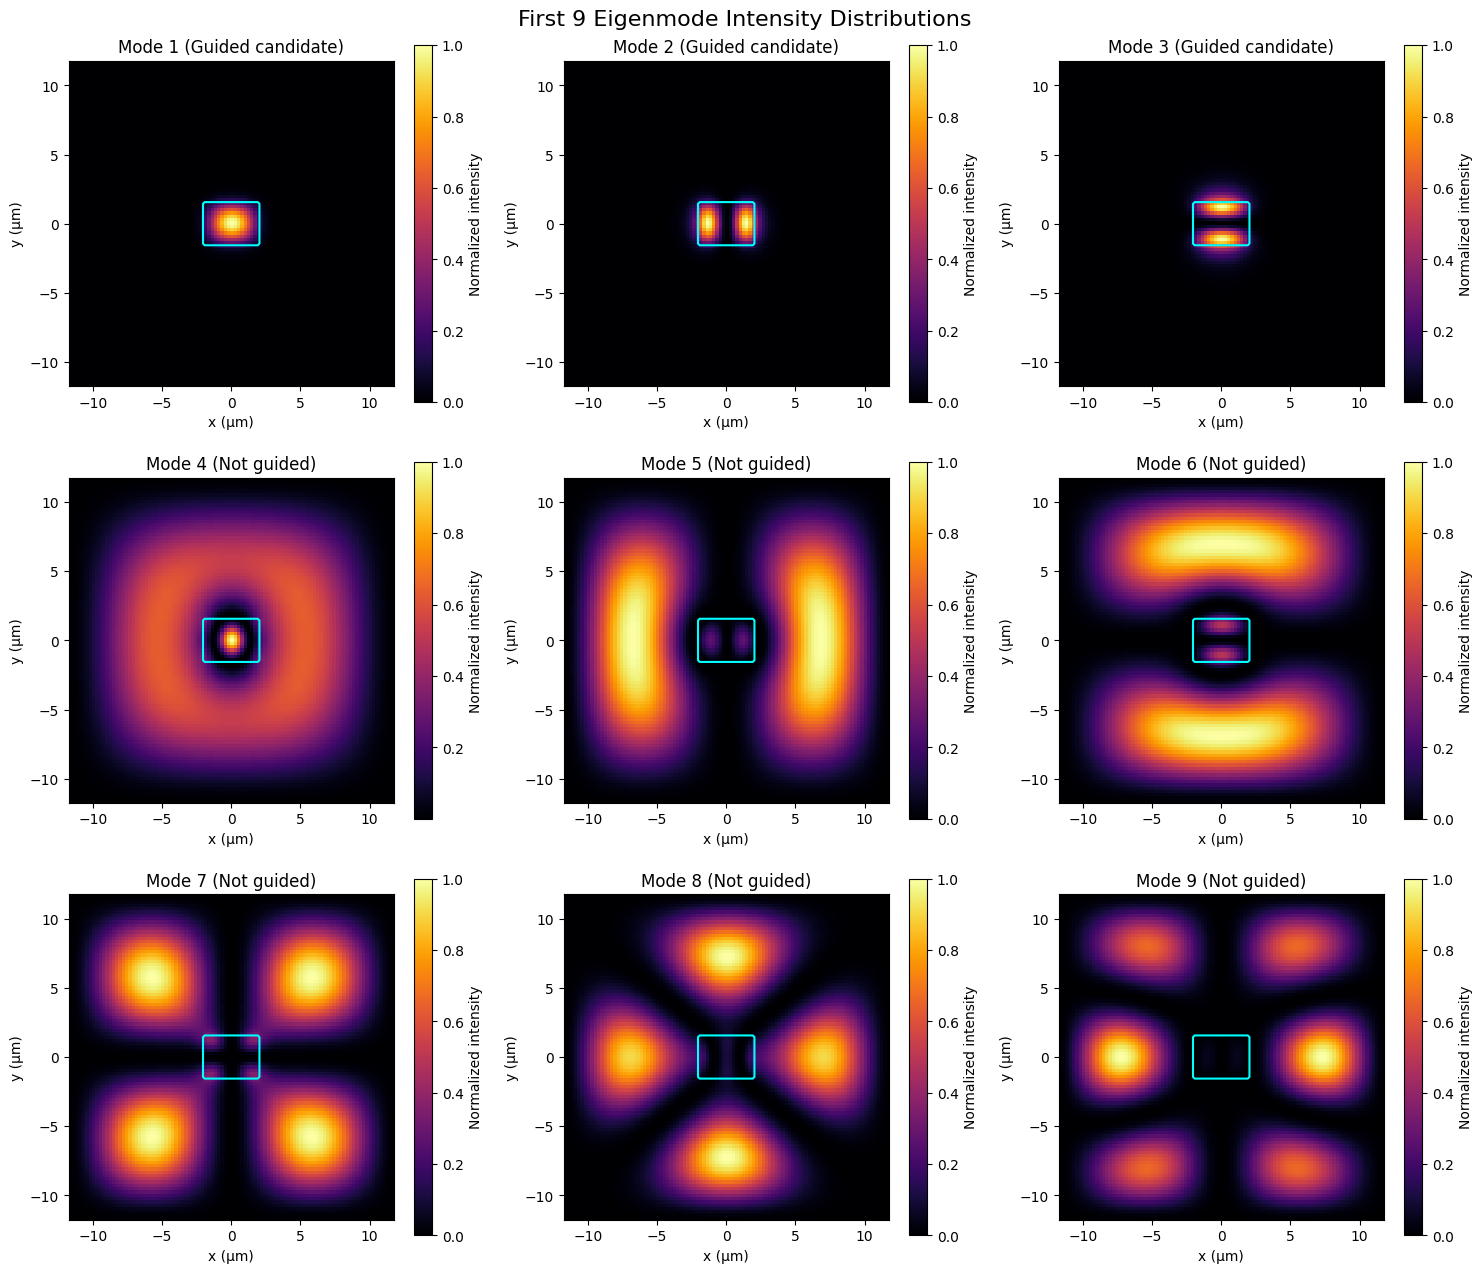

In [ ]:
# Display the first 9 calculated eigenmodes in a 3x3 grid

num_modes = min(9, eigenvectors.shape[1])

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

# Convert the axes into a single array for easy iteration
axes = axes.flatten()

for i in range(num_modes):

    ax = axes[i]

    # Get the eigenvector corresponding to the current mode
    psi = eigenvectors[:, i]

    # Convert the 1D eigenvector back into a 2D field distribution
    psi_2d = psi.reshape((ny_inner, nx_inner))

    # Normalize the field before calculating intensity
    psi_2d = psi_2d / np.max(np.abs(psi_2d))

    # Calculate the intensity distribution
    intensity = np.abs(psi_2d)**2

    # Plot the intensity distribution
    image = ax.imshow(
        intensity,
        extent=[
            x_inner[0] * 1e6,
            x_inner[-1] * 1e6,
            y_inner[0] * 1e6,
            y_inner[-1] * 1e6
        ],
        origin="lower",
        cmap="inferno",
        aspect="equal"
    )

    # Show the boundary of the waveguide core
    ax.contour(
        X * 1e6,
        Y * 1e6,
        core_mask.astype(float),
        levels=[0.5],
        colors="cyan"
    )

    # Identify whether the eigenmode satisfies our guided-mode condition
    if guided_mask[i]:
        mode_type = "Guided candidate"
    else:
        mode_type = "Not guided"

    ax.set_title(f"Mode {i + 1} ({mode_type})")
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")

    fig.colorbar(image, ax=ax, label="Normalized intensity")

# Hide unused plots if fewer than 9 eigenvectors are available
for i in range(num_modes, 9):
    axes[i].axis("off")

plt.suptitle("First 9 Eigenmode Intensity Distributions", fontsize=16)
plt.tight_layout()
plt.show()

### 9. Results and Physical Interpretation

For the parameters used in the original two-dimensional model, the numerical solver gives the first three effective refractive indices as approximately 1.483248, 1.464362 and 1.457213. These values lie between the cladding index (1.45) and core index (1.50), satisfying the basic effective-index test used here for guided-mode candidates.

The first mode has the largest effective index and is treated as the fundamental-mode candidate. Its field distribution is concentrated mainly around the high-index core. The higher modes have different transverse patterns and may contain multiple intensity lobes.

The field is not required to vanish immediately at the core boundary; it extends into the cladding. The calculated profiles therefore help visualise both confinement and the spatial structure of the modes.

These values are numerical results for the stated grid and boundary conditions. They should be checked by increasing the grid resolution and computational-domain size before being treated as converged physical values.

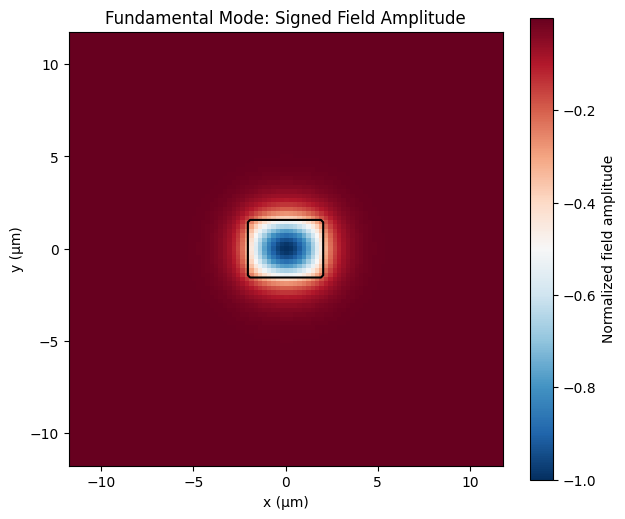

In [ ]:
if len(guided_modes) > 0:

    fundamental_mode = guided_modes[0]

    plt.figure(figsize=(7, 6))

    plt.imshow(
        np.real(fundamental_mode),
        extent=[
            x_inner[0] * 1e6,
            x_inner[-1] * 1e6,
            y_inner[0] * 1e6,
            y_inner[-1] * 1e6
        ],
        origin="lower",
        cmap="RdBu_r",
        aspect="equal"
    )

    plt.colorbar(label="Normalized field amplitude")

    plt.contour(
        X * 1e6,
        Y * 1e6,
        core_mask.astype(float),
        levels=[0.5],
        colors="black"
    )

    plt.xlabel("x (μm)")
    plt.ylabel("y (μm)")
    plt.title("Fundamental Mode: Signed Field Amplitude")

    plt.show()

### 10. Extension: Effect of Core Width on the Fundamental Mode

As an extension of the original problem, the effect of changing the core width on the fundamental-mode effective refractive index is investigated.

The core width is varied while the core height, refractive indices, wavelength and computational domain are kept constant.

For each width, the refractive-index profile and corresponding eigenvalue matrix are reconstructed. The largest eigenvalue is then calculated to obtain the fundamental-mode effective refractive index.

The results are plotted as a function of core width.

Increasing the core width generally improves the confinement of the fundamental mode within the high-index region. Consequently, its effective refractive index tends to move closer to the core refractive index.

This parameter study demonstrates how the geometry of an optical waveguide influences its modal propagation characteristics and illustrates the usefulness of numerical simulations in investigating waveguide design.

In [ ]:
def calculate_fundamental_neff(width):

    # Create the refractive-index profile
    n_test = np.full(
        (ny_inner, nx_inner),
        n_cladding
    )

    # Define the new core region
    mask = (
        (np.abs(X) <= width / 2) &
        (np.abs(Y) <= core_height / 2)
    )

    n_test[mask] = n_core

    # Convert the refractive index into a 1D array
    n_test_flat = n_test.ravel()

    # Construct the matrix for this core width
    A_test = D2D + diags(
        k0**2 * n_test_flat**2,
        offsets=0,
        format="csr"
    )

    # Calculate the largest eigenvalue
    values, vectors = eigsh(
        A_test,
        k=1,
        which="LA"
    )

    # Calculate the effective refractive index
    beta_test = np.sqrt(max(values[0], 0))
    neff_test = beta_test / k0

    return neff_test

In [ ]:
# Different core widths in micrometres
widths_um = np.array([2.0, 3.0, 4.0, 5.0, 6.0])

# Convert widths into metres
widths = widths_um * 1e-6

neff_values = []

for width in widths:

    neff_value = calculate_fundamental_neff(width)

    neff_values.append(neff_value)

    print(
        f"Width = {width * 1e6:.1f} μm, "
        f"Effective index = {neff_value:.6f}"
    )

Width = 2.0 μm, Effective index = 1.474491
Width = 3.0 μm, Effective index = 1.480158
Width = 4.0 μm, Effective index = 1.483248
Width = 5.0 μm, Effective index = 1.485091


Width = 6.0 μm, Effective index = 1.486272


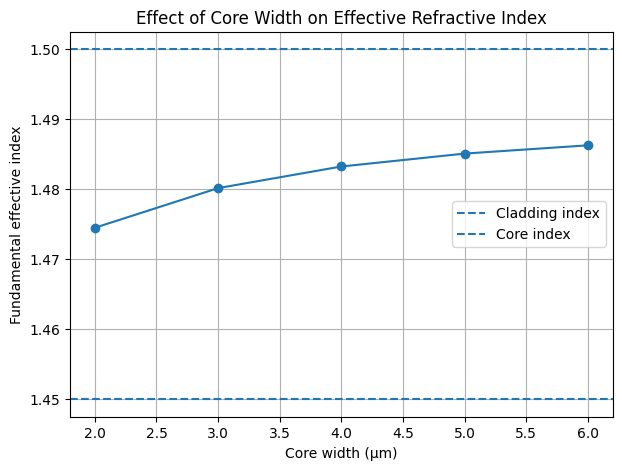

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(
    widths_um,
    neff_values,
    marker="o"
)

plt.axhline(
    n_cladding,
    linestyle="--",
    label="Cladding index"
)

plt.axhline(
    n_core,
    linestyle="--",
    label="Core index"
)

plt.xlabel("Core width (μm)")
plt.ylabel("Fundamental effective index")

plt.title("Effect of Core Width on Effective Refractive Index")

plt.legend()
plt.grid(True)

plt.show()

### 11. Extension I: Multilayer Cladding Design and Numerical Optimisation

A uniform cladding is replaced by three rectangular cladding layers surrounding the high-index core. Each layer is described by a refractive index $n_i$ and a thickness $t_i$. The refractive-index profile is therefore piecewise constant.

The layers are nested rectangular regions: layer 1 surrounds the core, layer 2 surrounds layer 1, and layer 3 surrounds layer 2. The region outside the third layer is assigned an outer-medium index $n_{\mathrm{out}}$.

For every candidate design, the finite-difference matrix is rebuilt and its largest eigenvalue and corresponding field are calculated. The effective index is

$$
n_{\mathrm{eff}}=\frac{\sqrt{\lambda_{\max}}}{k_0}.
$$

The design objective used here is to maximise the **core confinement factor**

$$
\Gamma_{\mathrm{core}}=
\frac{\sum_{(i,j)\in\mathrm{core}}|\psi_{ij}|^2}
{\sum_{(i,j)\in\mathrm{domain}}|\psi_{ij}|^2}.
$$

This quantity estimates the fraction of the scalar modal intensity located inside the core. It is a useful numerical design metric, but it is not identical to transmission efficiency or propagation loss.

A parameter sweep tests a range of layer thicknesses and selects the design with the largest calculated $\Gamma_{\mathrm{core}}$, subject to the basic effective-index condition $n_{\mathrm{out}}<n_{\mathrm{eff}}<n_{\mathrm{core}}$. The selected design and the full sweep are plotted. The search uses a coarser grid to keep the parameter study computationally manageable; the final selected design is then recalculated on the original grid.

**Interpretation:** the optimisation is conditional on the chosen material indices, wavelength, domain, grid and objective function. A different objective (for example, overlap with a Gaussian input beam) could select a different design.


Best thicknesses (t1, t2, t3) in micrometres: [0.4 0.4 0.4]
Effective index: 1.4867271170736467
Core confinement factor: 0.8890298693610565


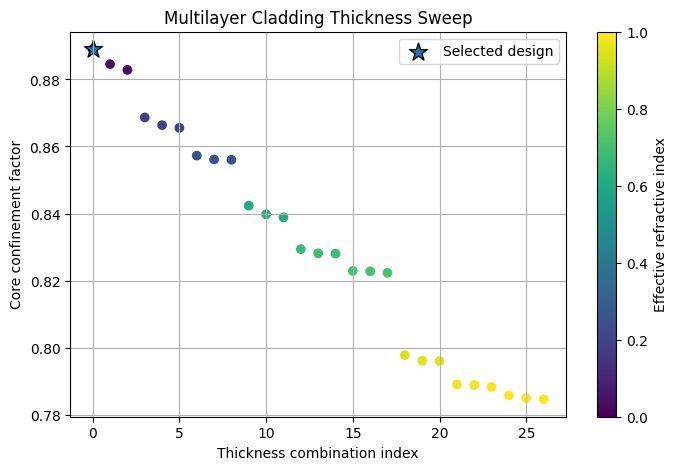

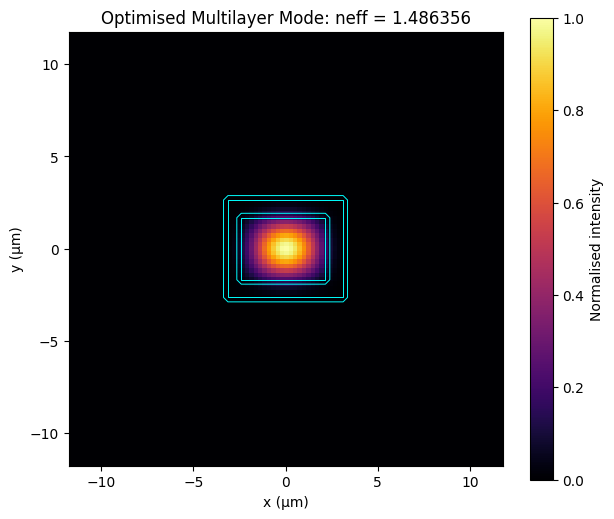

Refined-grid effective index: 1.486356082245086
Refined-grid core confinement factor: 0.8391552863603152


In [ ]:
# Multilayer design parameters
n_layer1 = 1.485
n_layer2 = 1.470
n_layer3 = 1.455
n_outer = 1.440

def layered_index_profile(Xg, Yg, core_w, core_h, thicknesses, indices):
    """Build a nested rectangular core / three-layer-cladding index profile."""
    t1, t2, t3 = thicknesses
    n1, n2, n3 = indices

    ax = np.abs(Xg)
    ay = np.abs(Yg)
    profile = np.full(Xg.shape, n_outer, dtype=float)

    # Assign outer-to-inner so inner layers overwrite the surrounding layers.
    profile[(ax <= core_w/2 + t1 + t2 + t3) &
            (ay <= core_h/2 + t1 + t2 + t3)] = n3
    profile[(ax <= core_w/2 + t1 + t2) &
            (ay <= core_h/2 + t1 + t2)] = n2
    profile[(ax <= core_w/2 + t1) &
            (ay <= core_h/2 + t1)] = n1
    profile[(ax <= core_w/2) & (ay <= core_h/2)] = n_core
    return profile


def solve_profile(profile, Xg, Yg, dxg, dyg, number_of_modes=1):
    """Solve the scalar 2D finite-difference eigenproblem for a given profile."""
    nyg, nxg = profile.shape
    main_xg = -2*np.ones(nxg)/dxg**2
    main_yg = -2*np.ones(nyg)/dyg**2
    off_xg = np.ones(nxg-1)/dxg**2
    off_yg = np.ones(nyg-1)/dyg**2

    Dxxg = diags([off_xg, main_xg, off_xg], [-1, 0, 1], format="csr")
    Dyyg = diags([off_yg, main_yg, off_yg], [-1, 0, 1], format="csr")
    Dg = kron(eye(nyg, format="csr"), Dxxg) + kron(Dyyg, eye(nxg, format="csr"))
    Ag = Dg + diags(k0**2 * profile.ravel()**2, 0, format="csr")

    vals, vecs = eigsh(Ag, k=number_of_modes, which="LA")
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    vals = np.maximum(vals, 0)
    return np.sqrt(vals)/k0, vecs


def core_confinement(field, core_w, core_h, Xg, Yg):
    """Return the fraction of |field|^2 lying inside the rectangular core."""
    mask = (np.abs(Xg) <= core_w/2) & (np.abs(Yg) <= core_h/2)
    intensity = np.abs(field)**2
    return np.sum(intensity[mask])/np.sum(intensity)


# Use a coarser mesh for the design sweep; refine the selected design afterwards.
N_search = 51
x_search = np.linspace(-lx, lx, N_search)
y_search = np.linspace(-ly, ly, N_search)
dx_search = x_search[1] - x_search[0]
dy_search = y_search[1] - y_search[0]
X_search, Y_search = np.meshgrid(x_search[1:-1], y_search[1:-1], indexing="xy")

thickness_values_um = [0.4, 0.8, 1.2]
thickness_combinations = []
confinement_values = []
neff_values_multilayer = []

for t1_um in thickness_values_um:
    for t2_um in thickness_values_um:
        for t3_um in thickness_values_um:
            thicknesses = np.array([t1_um, t2_um, t3_um])*1e-6
            profile = layered_index_profile(
                X_search, Y_search, core_width, core_height,
                thicknesses, [n_layer1, n_layer2, n_layer3]
            )
            neff_result, field_vector = solve_profile(
                profile, X_search, Y_search, dx_search, dy_search
            )
            field = field_vector[:, 0].reshape(profile.shape)
            gamma_core = core_confinement(
                field, core_width, core_height, X_search, Y_search
            )
            thickness_combinations.append([t1_um, t2_um, t3_um])
            confinement_values.append(gamma_core)
            neff_values_multilayer.append(neff_result[0])

thickness_combinations = np.asarray(thickness_combinations)
confinement_values = np.asarray(confinement_values)
neff_values_multilayer = np.asarray(neff_values_multilayer)

guided_design = (
    (neff_values_multilayer > n_outer) &
    (neff_values_multilayer < n_core)
)
if not np.any(guided_design):
    raise RuntimeError("No candidate design met the selected effective-index condition.")

valid_indices = np.where(guided_design)[0]
best_index = valid_indices[np.argmax(confinement_values[guided_design])]
best_thicknesses_um = thickness_combinations[best_index]
best_thicknesses = best_thicknesses_um*1e-6

print("Best thicknesses (t1, t2, t3) in micrometres:", best_thicknesses_um)
print("Effective index:", neff_values_multilayer[best_index])
print("Core confinement factor:", confinement_values[best_index])

plt.figure(figsize=(8, 5))
plt.scatter(
    np.arange(len(confinement_values)), confinement_values,
    c=neff_values_multilayer, cmap="viridis"
)
plt.scatter(best_index, confinement_values[best_index],
            marker="*", s=180, edgecolor="black", label="Selected design")
plt.xlabel("Thickness combination index")
plt.ylabel("Core confinement factor")
plt.title("Multilayer Cladding Thickness Sweep")
plt.colorbar(label="Effective refractive index")
plt.legend()
plt.grid(True)
plt.show()

# Recalculate the selected multilayer design on the original, finer grid.
best_profile = layered_index_profile(
    X, Y, core_width, core_height, best_thicknesses,
    [n_layer1, n_layer2, n_layer3]
)
best_neff, best_vectors = solve_profile(best_profile, X, Y, dx, dy)
best_field = best_vectors[:, 0].reshape(best_profile.shape)
best_field = best_field/np.max(np.abs(best_field))
best_gamma = core_confinement(best_field, core_width, core_height, X, Y)

plt.figure(figsize=(7, 6))
plt.imshow(
    np.abs(best_field)**2,
    extent=[x_inner[0]*1e6, x_inner[-1]*1e6,
            y_inner[0]*1e6, y_inner[-1]*1e6],
    origin="lower", cmap="inferno", aspect="equal"
)
plt.colorbar(label="Normalised intensity")
plt.contour(X*1e6, Y*1e6, best_profile, levels=4, colors="cyan", linewidths=0.7)
plt.xlabel("x (μm)")
plt.ylabel("y (μm)")
plt.title(f"Optimised Multilayer Mode: neff = {best_neff[0]:.6f}")
plt.show()

print("Refined-grid effective index:", best_neff[0])
print("Refined-grid core confinement factor:", best_gamma)


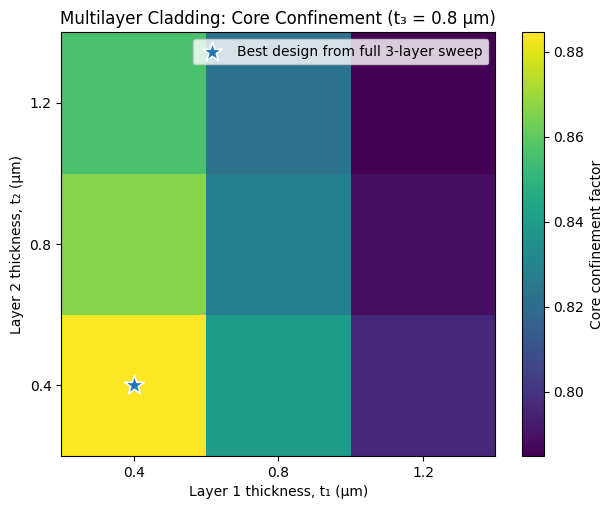

In [ ]:
# Compare the confinement factor as the first two layer thicknesses vary,
# while keeping the third layer thickness fixed.
fixed_t3_um = thickness_values_um[1]
heatmap = np.full((len(thickness_values_um), len(thickness_values_um)), np.nan)

for idx, (t1_um, t2_um, t3_um) in enumerate(thickness_combinations):
    if np.isclose(t3_um, fixed_t3_um):
        row = np.where(np.isclose(thickness_values_um, t2_um))[0][0]
        col = np.where(np.isclose(thickness_values_um, t1_um))[0][0]
        heatmap[row, col] = confinement_values[idx]

plt.figure(figsize=(7, 5.5))
image = plt.imshow(
    heatmap,
    origin="lower",
    extent=[min(thickness_values_um)-0.2, max(thickness_values_um)+0.2,
            min(thickness_values_um)-0.2, max(thickness_values_um)+0.2],
    aspect="auto",
    cmap="viridis"
)
plt.colorbar(image, label="Core confinement factor")
plt.scatter(best_thicknesses_um[0], best_thicknesses_um[1],
            marker="*", s=220, edgecolor="white", linewidth=1.2,
            label="Best design from full 3-layer sweep")
plt.xticks(thickness_values_um)
plt.yticks(thickness_values_um)
plt.xlabel("Layer 1 thickness, t₁ (μm)")
plt.ylabel("Layer 2 thickness, t₂ (μm)")
plt.title(f"Multilayer Cladding: Core Confinement (t₃ = {fixed_t3_um:.1f} μm)")
plt.legend()
plt.grid(False)
plt.show()

### 12. Extension II: Monte Carlo Search for Refractive Indices

The second extension uses random sampling to explore possible material combinations. The three cladding refractive indices are generated using a random-number generator, while the layer thicknesses are held fixed. Samples are retained only when the indices satisfy the physically chosen ordering

$$
n_{\mathrm{core}}>n_1>n_2>n_3>n_{\mathrm{out}}.
$$

For each accepted material combination, the refractive-index profile and finite-difference matrix are reconstructed. The largest eigenvalue gives the effective index of the fundamental-mode candidate. A design is accepted when

$$
|n_{\mathrm{eff}}-n_{\mathrm{target}}|\leq \epsilon.
$$

This is a Monte Carlo parameter search: it does not guarantee the global optimum, but it can identify candidate combinations close to a specified effective-index target. The number of random trials and the tolerance affect the number of accepted designs.


Random trials: 250
Valid material combinations solved: 250
Accepted designs within target tolerance: 40

Accepted designs: n1, n2, n3, neff
[[1.48670301 1.46800326 1.45167832 1.48866337]
 [1.48828586 1.4632487  1.45729969 1.48862399]
 [1.48589993 1.4780831  1.47321476 1.4893793 ]
 [1.49120418 1.45403637 1.44349816 1.48850322]
 [1.48884122 1.46438321 1.45001838 1.4887118 ]
 [1.48316778 1.47763853 1.46592558 1.48894864]
 [1.48696411 1.4691995  1.4449638  1.48872831]
 [1.48361968 1.47956536 1.45687403 1.48906489]
 [1.49620879 1.45574763 1.45445823 1.48918987]
 [1.48165575 1.474867   1.45198654 1.48849975]
 [1.49565375 1.44786347 1.44742523 1.48878404]
 [1.48947985 1.45862008 1.44863232 1.48851384]
 [1.49525823 1.4570832  1.4499319  1.48911875]
 [1.48084287 1.47546863 1.46361783 1.48852498]
 [1.49000751 1.47142518 1.44610031 1.48921571]
 [1.49549051 1.44594679 1.44311771 1.48868749]
 [1.48673978 1.47216408 1.44807313 1.48888372]
 [1.48409359 1.48168789 1.45214428 1.48924585]
 [1.4858354  1

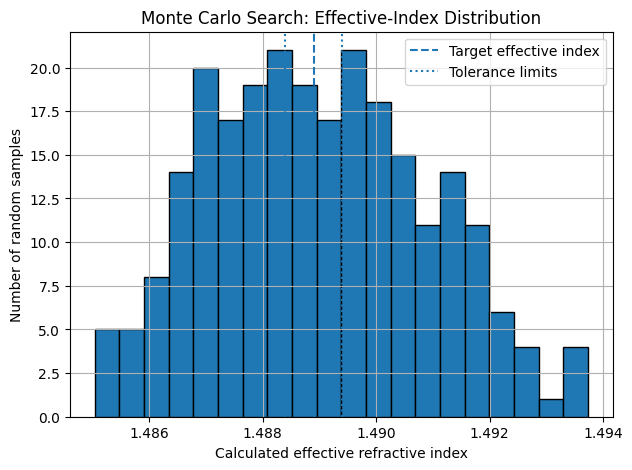

In [ ]:
# Monte Carlo search settings
rng = np.random.default_rng(42)
number_of_trials = 250
target_neff = 1.4889
neff_tolerance = 5e-4

# Keep the layer thicknesses fixed and randomly sample the three indices.
mc_thicknesses = np.array([0.8, 0.8, 0.8])*1e-6
accepted_designs = []
sampled_neff = []

for trial in range(number_of_trials):
    random_indices = np.sort(
        rng.uniform(n_outer, n_core, size=3)
    )[::-1]

    n1_trial, n2_trial, n3_trial = random_indices
    if not (n_core > n1_trial > n2_trial > n3_trial > n_outer):
        continue

    trial_profile = layered_index_profile(
        X_search, Y_search, core_width, core_height,
        mc_thicknesses, random_indices
    )
    trial_neff, trial_vectors = solve_profile(
        trial_profile, X_search, Y_search, dx_search, dy_search
    )
    neff_value = trial_neff[0]
    sampled_neff.append(neff_value)

    if abs(neff_value - target_neff) <= neff_tolerance:
        accepted_designs.append(
            [n1_trial, n2_trial, n3_trial, neff_value]
        )

accepted_designs = np.asarray(accepted_designs)
sampled_neff = np.asarray(sampled_neff)

print("Random trials:", number_of_trials)
print("Valid material combinations solved:", len(sampled_neff))
print("Accepted designs within target tolerance:", len(accepted_designs))

if len(accepted_designs) > 0:
    print("\nAccepted designs: n1, n2, n3, neff")
    print(accepted_designs)
else:
    print("No design met the target. Increase the trial count or adjust the target/tolerance.")

plt.figure(figsize=(7, 5))
plt.hist(sampled_neff, bins=20, edgecolor="black")
plt.axvline(target_neff, linestyle="--", label="Target effective index")
plt.axvline(target_neff-neff_tolerance, linestyle=":", label="Tolerance limits")
plt.axvline(target_neff+neff_tolerance, linestyle=":")
plt.xlabel("Calculated effective refractive index")
plt.ylabel("Number of random samples")
plt.title("Monte Carlo Search: Effective-Index Distribution")
plt.legend()
plt.grid(True)
plt.show()


### 13. Discussion, Strengths and Limitations

The finite-difference eigenvalue method converts the scalar wave equation into a sparse matrix eigenvalue problem. It provides both the propagation constants and transverse mode shapes for a two-dimensional refractive-index profile. The multilayer sweep demonstrates how layer geometry can be explored computationally, while the Monte Carlo search demonstrates how random material selection can target a desired effective index.

The method has several limitations. First, it uses a scalar Helmholtz approximation rather than a full-vector Maxwell solver, so polarisation and vector-field effects are not fully represented. Second, the zero-field outer boundary is an approximation; the computational domain must be sufficiently large that the field has decayed before reaching the boundary. Third, the results depend on grid spacing and should be checked for convergence. Finally, the confinement factor and effective index alone do not model absorption, scattering, fabrication tolerances or total transmission loss.

The optimisation is also conditional on the chosen search ranges and discrete thickness values. The Monte Carlo method is stochastic and may miss suitable designs when the number of trials is small. Repeating the search with a different random seed or increasing the number of trials can help assess sampling variability.